<a href="https://colab.research.google.com/github/PriyankaDevaprasad/Aerial_object_classification/blob/main/Aerial_Object_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Aerial Object Classification Using Deep Learning**

**Project Description**

The Aerial Object Classification project uses deep learning to classify aerial images into two categories: Bird and Drone. It uses CNN and ResNet50 models and deploys the trained model through a Streamlit web application for image-based prediction.

**Problem Statement**
Birds and drones can appear visually similar in aerial images, making manual identification difficult. An automated deep learning system is needed to classify aerial images accurately and efficiently as birds or drones.

**Importing necessary libraries**

In [ ]:
import os
import random
import json
import copy
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image, ImageFile

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, transforms, models
from sklearn.model_selection import train_test_split

print("PyTorch:", torch.__version__)
print("TorchVision:", __import__("torchvision").__version__)

PyTorch: 2.11.0+cpu
TorchVision: 0.26.0+cpu


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


**Inspect dataset folder structure**

In [ ]:

dataset_path = '/content/drive/MyDrive/Bird_drone'

for folder in os.listdir(dataset_path):
    full_path = os.path.join(dataset_path, folder)

    if os.path.isdir(full_path):
        print(folder)

        for subfolder in os.listdir(full_path):
            print("   ", subfolder)

valid
    drone
    bird
train
    bird
    drone
test
    bird
    drone


**Checking number of images per class and identifying imbalance**

In [ ]:
data = []

for split in ["train", "valid", "test"]:
    bird_count = len(os.listdir(f"{dataset_path}/{split}/bird"))
    drone_count = len(os.listdir(f"{dataset_path}/{split}/drone"))

    data.append([split.capitalize(), bird_count, drone_count,
                 bird_count + drone_count])

df = pd.DataFrame(data, columns=["Dataset", "Bird", "Drone", "Total Images"])

display(df)


,Dataset,Bird,Drone,Total Images
0,Train,1415,1249,2664
1,Valid,217,225,442
2,Test,121,94,215


**Visualize sample images**

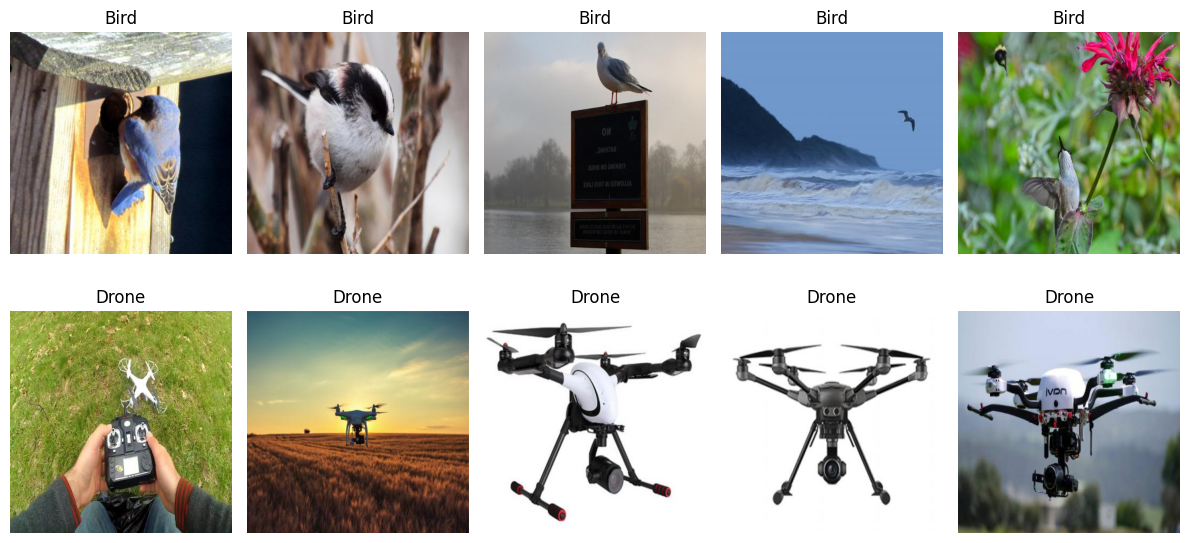

In [ ]:

plt.figure(figsize=(12, 6))

for i, category in enumerate(["bird", "drone"]):

    folder = os.path.join(dataset_path, "train", category)
    images = os.listdir(folder)
    samples = random.sample(images, 5)

    for j, image_name in enumerate(samples):
        img = Image.open(os.path.join(folder, image_name))

        plt.subplot(2, 5, i * 5 + j + 1)
        plt.imshow(img)
        plt.title(category.capitalize())
        plt.axis("off")

plt.tight_layout()
plt.show()

# **Data Preprocessing and data augmentation**

In [ ]:
# Training transformations: augmentation + normalization
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomRotation(15),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.2),
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
    transforms.ColorJitter(brightness=0.2),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Validation and test: no random augmentation
eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Load datasets
train_dataset = datasets.ImageFolder(os.path.join(dataset_path, "train"),transform=train_transform)
valid_dataset = datasets.ImageFolder(os.path.join(dataset_path, "valid"),transform=eval_transform)
test_dataset = datasets.ImageFolder(os.path.join(dataset_path, "test"),transform=eval_transform)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
valid_loader = DataLoader(valid_dataset, batch_size=32, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

print("Class labels:", train_dataset.class_to_idx)

Class labels: {'bird': 0, 'drone': 1}


In [ ]:
images, labels = next(iter(train_loader))

print("Images shape:", images.shape)
print("Labels shape:", labels.shape)

Images shape: torch.Size([32, 3, 224, 224])
Labels shape: torch.Size([32])


**Custom CNN**

In [ ]:
class CustomCNN(nn.Module):

    def __init__(self):
        super().__init__()

        # Convolutional layers
        self.conv = nn.Sequential(nn.Conv2d(3, 32, kernel_size=3),nn.ReLU(),nn.MaxPool2d(2),
                                  nn.Conv2d(32, 64, kernel_size=3),nn.ReLU(),nn.MaxPool2d(2),
                                  nn.Conv2d(64, 128, kernel_size=3),nn.ReLU(),nn.MaxPool2d(2))

        # Fully connected layers
        self.fc = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 26 * 26, 128),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(128, 2)
        )

    def forward(self, x):
        x = self.conv(x)
        x = self.fc(x)
        return x
model = CustomCNN()
print(model)

CustomCNN(
  (conv): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (fc): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=86528, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.5, inplace=False)
    (4): Linear(in_features=128, out_features=2, bias=True)
  )
)


**Transfer Learning:ResNet**

In [ ]:
from torchvision import models
import torch.nn as nn

resnet50 = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)

# Freeze the pretrained layers
for param in resnet50.parameters():
    param.requires_grad = False

# Replace the final layer for Bird vs Drone
resnet50.fc = nn.Linear(resnet50.fc.in_features,2)

print("ResNet50 is ready!")
print("Classes:", train_dataset.classes)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 133MB/s]


ResNet50 is ready!
Classes: ['bird', 'drone']


**Model Training**

In [ ]:
import time
import torch.optim as optim
from sklearn.metrics import precision_recall_fscore_support

def train_model(model, name, epochs=15, patience=3):

    criterion = nn.CrossEntropyLoss()

    optimizer = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()),lr=0.001)

    history = {
        "train_loss": [],
        "val_loss": [],
        "train_accuracy": [],
        "val_accuracy": [],
        "val_precision": [],
        "val_recall": [],
        "val_f1": []
    }

    best_loss = float("inf")
    best_weights = copy.deepcopy(model.state_dict())
    wait = 0

    start_time = time.time()

    for epoch in range(epochs):

        # Training phase
        model.train()

        running_loss = 0
        correct = 0
        total = 0

        for images, labels in train_loader:

            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            running_loss += loss.item() * images.size(0)
            predictions = outputs.argmax(dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

        train_loss = running_loss / total
        train_accuracy = correct / total

        # Validation phase
        model.eval()

        val_loss = 0
        y_true = []
        y_pred = []

        with torch.no_grad():

            for images, labels in valid_loader:

                images = images.to(device)
                labels = labels.to(device)

                outputs = model(images)
                loss = criterion(outputs, labels)

                val_loss += loss.item() * images.size(0)

                predictions = outputs.argmax(dim=1)

                y_true.extend(labels.cpu().numpy())
                y_pred.extend(predictions.cpu().numpy())

        val_loss = val_loss / len(valid_loader.dataset)

        val_accuracy = accuracy_score(y_true, y_pred)

        val_precision, val_recall, val_f1, _ = (precision_recall_fscore_support(y_true,y_pred,average="weighted",zero_division=0))

        # Store metrics
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_accuracy"].append(train_accuracy)
        history["val_accuracy"].append(val_accuracy)
        history["val_precision"].append(val_precision)
        history["val_recall"].append(val_recall)
        history["val_f1"].append(val_f1)

        print(
            f"{name} | Epoch {epoch + 1}/{epochs} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Train Acc: {train_accuracy:.4f} | "
            f"Val Acc: {val_accuracy:.4f} | "
            f"Precision: {val_precision:.4f} | "
            f"Recall: {val_recall:.4f} | "
            f"F1: {val_f1:.4f}"
        )

        # Model Checkpoint: save best validation-loss model
        if val_loss < best_loss:

            best_loss = val_loss
            best_weights = copy.deepcopy(model.state_dict())

            torch.save(
                best_weights,
                f"{name}_best.pth"
            )

            wait = 0

        else:
            wait += 1

        # Early Stopping
        if wait >= patience:
            print("Early stopping triggered!")
            break

    # Restore best weights
    model.load_state_dict(best_weights)

    training_time = time.time() - start_time

    print(f"\n{name} training completed.")
    print(f"Training time: {training_time:.2f} seconds")

    return model, history, training_time

**Train Custom CNN**

In [ ]:
# Define device first since it is used inside train_model
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Instantiate the custom model with the correct variable name
custom_model = CustomCNN().to(device)

# Train the model
custom_model, custom_history, custom_time = train_model(
    custom_model,
    "CustomCNN"
)

CustomCNN | Epoch 1/15 | Train Loss: 0.7403 | Val Loss: 0.5672 | Train Acc: 0.6625 | Val Acc: 0.6900 | Precision: 0.7072 | Recall: 0.6900 | F1: 0.6848
CustomCNN | Epoch 2/15 | Train Loss: 0.5593 | Val Loss: 0.4720 | Train Acc: 0.7065 | Val Acc: 0.7421 | Precision: 0.7585 | Recall: 0.7421 | F1: 0.7388
CustomCNN | Epoch 3/15 | Train Loss: 0.4909 | Val Loss: 0.4451 | Train Acc: 0.7459 | Val Acc: 0.7805 | Precision: 0.7812 | Recall: 0.7805 | F1: 0.7805
CustomCNN | Epoch 4/15 | Train Loss: 0.4661 | Val Loss: 0.4627 | Train Acc: 0.7721 | Val Acc: 0.7557 | Precision: 0.7627 | Recall: 0.7557 | F1: 0.7534
CustomCNN | Epoch 5/15 | Train Loss: 0.4450 | Val Loss: 0.5251 | Train Acc: 0.7827 | Val Acc: 0.7715 | Precision: 0.8172 | Recall: 0.7715 | F1: 0.7640
CustomCNN | Epoch 6/15 | Train Loss: 0.4286 | Val Loss: 0.5419 | Train Acc: 0.8041 | Val Acc: 0.7489 | Precision: 0.7745 | Recall: 0.7489 | F1: 0.7418
Early stopping triggered!

CustomCNN training completed.
Training time: 3970.45 seconds


**Train ResNet50**

In [ ]:
# Assign the configured ResNet50 model to resnet_model
resnet_model = resnet50.to(device)
# Train the model
resnet_model, resnet_history, resnet_time = train_model(resnet_model,"ResNet50")

ResNet50 | Epoch 1/15 | Train Loss: 0.2586 | Val Loss: 0.1103 | Train Acc: 0.9099 | Val Acc: 0.9661 | Precision: 0.9668 | Recall: 0.9661 | F1: 0.9660
ResNet50 | Epoch 2/15 | Train Loss: 0.1126 | Val Loss: 0.0803 | Train Acc: 0.9655 | Val Acc: 0.9729 | Precision: 0.9738 | Recall: 0.9729 | F1: 0.9728
ResNet50 | Epoch 3/15 | Train Loss: 0.0905 | Val Loss: 0.0587 | Train Acc: 0.9726 | Val Acc: 0.9887 | Precision: 0.9887 | Recall: 0.9887 | F1: 0.9887
ResNet50 | Epoch 4/15 | Train Loss: 0.0683 | Val Loss: 0.0548 | Train Acc: 0.9809 | Val Acc: 0.9864 | Precision: 0.9866 | Recall: 0.9864 | F1: 0.9864
ResNet50 | Epoch 5/15 | Train Loss: 0.0615 | Val Loss: 0.0438 | Train Acc: 0.9797 | Val Acc: 0.9842 | Precision: 0.9842 | Recall: 0.9842 | F1: 0.9842
ResNet50 | Epoch 6/15 | Train Loss: 0.0589 | Val Loss: 0.0435 | Train Acc: 0.9824 | Val Acc: 0.9864 | Precision: 0.9865 | Recall: 0.9864 | F1: 0.9864
ResNet50 | Epoch 7/15 | Train Loss: 0.0520 | Val Loss: 0.0436 | Train Acc: 0.9846 | Val Acc: 0.9842 

**Comparison Graph**

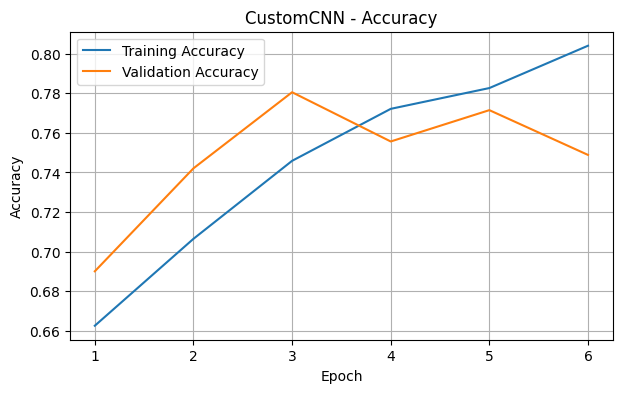

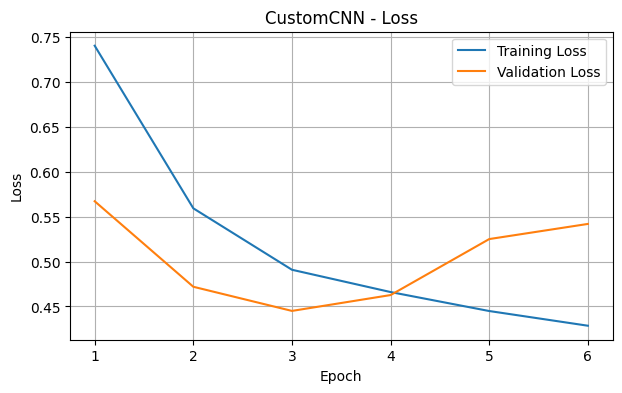

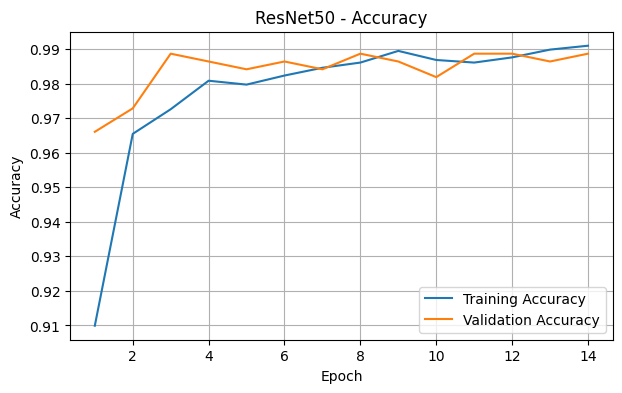

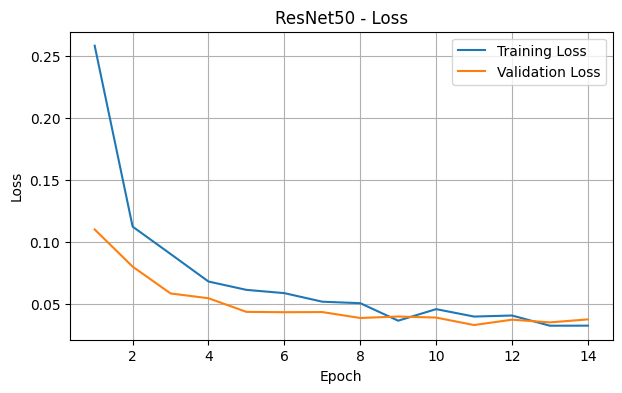

In [ ]:
histories = {"CustomCNN": custom_history,"ResNet50": resnet_history}

for name, history in histories.items():

    epochs = range(1, len(history["train_loss"]) + 1)

    # Accuracy graph
    plt.figure(figsize=(7, 4))
    plt.plot(epochs, history["train_accuracy"],label="Training Accuracy")
    plt.plot(epochs, history["val_accuracy"],label="Validation Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.title(f"{name} - Accuracy")
    plt.legend()
    plt.grid(True)
    plt.show()

    # Loss graph
    plt.figure(figsize=(7, 4))
    plt.plot(epochs, history["train_loss"],label="Training Loss")
    plt.plot(epochs, history["val_loss"],label="Validation Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title(f"{name} - Loss")
    plt.legend()
    plt.grid(True)
    plt.show()

**Model Evaluation**

In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score, ConfusionMatrixDisplay, classification_report, confusion_matrix, accuracy_score
import matplotlib.pyplot as plt

def evaluate_model(model, name):

    model.eval()
    y_true = []
    y_pred = []

    with torch.no_grad():

        for images, labels in test_loader:
            images = images.to(device)
            outputs = model(images)
            predictions = outputs.argmax(dim=1)
            y_true.extend(labels.numpy())
            y_pred.extend(predictions.cpu().numpy())

    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, average="weighted", zero_division=0)
    recall = recall_score(y_true, y_pred, average="weighted", zero_division=0)
    f1 = f1_score(y_true, y_pred, average="weighted", zero_division=0)
    print(f"\n{'=' * 40}")
    print(name)
    print(f"{'=' * 40}")
    print(f"Accuracy : {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall   : {recall:.4f}")
    print(f"F1-score : {f1:.4f}")

    print("\nClassification Report:\n")
    print(classification_report(y_true,y_pred,labels=list(range(len(test_dataset.classes))),target_names=test_dataset.classes,zero_division=0))

    # Confusion matrix
    cm = confusion_matrix(y_true,y_pred,labels=list(range(len(test_dataset.classes))))
    display_plot = ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=test_dataset.classes)
    display_plot.plot(values_format="d")
    plt.title(f"{name} - Test Confusion Matrix")
    plt.show()
    return {"Model": name,"Accuracy": accuracy,"Precision": precision,"Recall": recall,"F1-score": f1}


CustomCNN
Accuracy : 0.8372
Precision: 0.8398
Recall   : 0.8372
F1-score : 0.8353

Classification Report:

              precision    recall  f1-score   support

        bird       0.82      0.91      0.86       121
       drone       0.86      0.74      0.80        94

    accuracy                           0.84       215
   macro avg       0.84      0.83      0.83       215
weighted avg       0.84      0.84      0.84       215



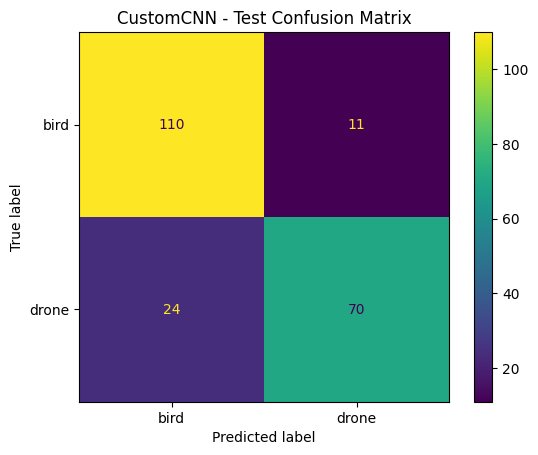


ResNet50
Accuracy : 0.9860
Precision: 0.9864
Recall   : 0.9860
F1-score : 0.9860

Classification Report:

              precision    recall  f1-score   support

        bird       0.98      1.00      0.99       121
       drone       1.00      0.97      0.98        94

    accuracy                           0.99       215
   macro avg       0.99      0.98      0.99       215
weighted avg       0.99      0.99      0.99       215



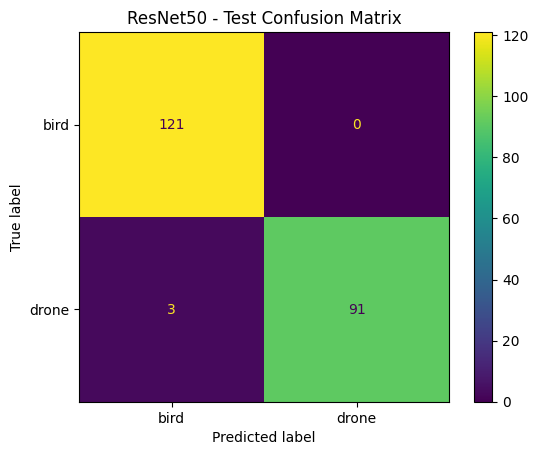

In [ ]:
custom_results = evaluate_model(custom_model, "CustomCNN")
resnet_results = evaluate_model(resnet_model, "ResNet50")

In [ ]:
comparison = pd.DataFrame([
    {
        **custom_results,
        "Training Time (seconds)": custom_time
    },
    {
        **resnet_results,
        "Training Time (seconds)": resnet_time
    }
])

display(comparison.round(4))


,Model,Accuracy,Precision,Recall,F1-score,Training Time (seconds)
0,CustomCNN,0.8372,0.8398,0.8372,0.8353,3970.4502
1,ResNet50,0.9860,0.9864,0.9860,0.9860,14273.0080


In [ ]:
generalization = pd.DataFrame([
    {
        "Model": "CustomCNN",
        "Best Validation Accuracy": max(
            custom_history["val_accuracy"]
        ),
        "Test Accuracy": custom_results["Accuracy"]
    },
    {
        "Model": "ResNet50",
        "Best Validation Accuracy": max(
            resnet_history["val_accuracy"]
        ),
        "Test Accuracy": resnet_results["Accuracy"]
    }
])

generalization["Validation-Test Gap"] = (
    generalization["Best Validation Accuracy"]
    - generalization["Test Accuracy"]
)

display(generalization.round(4))

,Model,Best Validation Accuracy,Test Accuracy,Validation-Test Gap
0,CustomCNN,0.7805,0.8372,-0.0567
1,ResNet50,0.9887,0.9860,0.0026


In [ ]:
custom_best_f1 = max(custom_history["val_f1"])
resnet_best_f1 = max(resnet_history["val_f1"])

if resnet_best_f1 > custom_best_f1:
    best_model = resnet_model
    best_model_name = "ResNet50"
else:
    best_model = custom_model
    best_model_name = "CustomCNN"

print("Selected model:", best_model_name)
print("Custom CNN best validation F1:", round(custom_best_f1, 4))
print("ResNet50 best validation F1:", round(resnet_best_f1, 4))

Selected model: ResNet50
Custom CNN best validation F1: 0.7805
ResNet50 best validation F1: 0.9887


In [ ]:
import os
import torch

save_path = "/content/drive/MyDrive/Bird_Drone_Project"
os.makedirs(save_path, exist_ok=True)

torch.save(
    best_model.state_dict(),
    os.path.join(save_path, "best_model.pth")
)

print("Best model saved successfully!")

Best model saved successfully!


In [ ]:
with open(os.path.join(save_path, "model_name.txt"), "w") as f:
    f.write(best_model_name)

print("Model type saved:", best_model_name)

Model type saved: ResNet50


# **Streamlit Application**

In [ ]:
import os

save_path = "/content/drive/MyDrive/Bird_Drone_Project"

print(os.listdir(save_path))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
['best_model.pth', 'model_name.txt']


In [ ]:
import json

class_names = train_dataset.classes

with open(os.path.join(save_path, "class_names.json"), "w") as f:
    json.dump(class_names, f)

print("Class names saved:", class_names)

Class names saved: ['bird', 'drone']


In [ ]:
!pip install -q streamlit
!wget https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64
!chmod +x cloudflared-linux-amd64
import subprocess
subprocess.Popen(["./cloudflared-linux-amd64", "tunnel", "--url", "http://localhost:8501"])
!nohup /content/cloudflared-linux-amd64 tunnel --url http://localhost:8501 &

--2026-10-15 07:05:48--  https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64
Resolving github.com (github.com)... 20.205.243.166
Connecting to github.com (github.com)|20.205.243.166|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://github.com/cloudflare/cloudflared/releases/download/2026.10.0/cloudflared-linux-amd64 [following]
--2026-10-15 07:05:48--  https://github.com/cloudflare/cloudflared/releases/download/2026.10.0/cloudflared-linux-amd64
Reusing existing connection to github.com:443.
HTTP request sent, awaiting response... 302 Found
Location: https://release-assets.githubusercontent.com/github-production-release-asset/106867604/96692278-72f4-40bc-b493-dbd69628f37a?sp=r&sv=2018-11-09&sr=b&spr=https&se=2026-10-15T08%3A03%3A28Z&rscd=attachment%3B+filename%3Dcloudflared-linux-amd64&rsct=application%2Foctet-stream&skoid=96c2d410-5711-43a1-aedd-ab1947aa7ab0&sktid=398a6654-997b-47e9-b12b-9515b896b4de&skt=2026-1

In [ ]:
%%writefile app.py

import os
import json
import torch
import torch.nn as nn
import streamlit as st

from PIL import Image
from torchvision import models, transforms


# Page configuration
st.set_page_config(
    page_title="Aerial Object Classification",
    page_icon="🐦"
)

st.markdown("""
<style>

.hero {
    background: linear-gradient(120deg, #12345a, #1976d2);
    padding: 32px;
    border-radius: 20px;
    color: white;
    margin-bottom: 25px;
}
.hero h1 {
    color: white;
    font-size: 38px;
    margin-bottom: 8px;
}
.hero p {
    color: #e2efff;
    font-size: 17px;
}
.section-title {
    font-size: 23px;
    font-weight: 700;
    color: #17365d;
    margin: 10px 0 18px 0;
}
.result-card {
    background: linear-gradient(120deg, #e0f7ec, #f4fff8);
    border: 1px solid #a7e5c3;
    border-radius: 16px;
    padding: 24px;
    margin: 15px 0;
}
.result-label {
    color: #167447;
    font-size: 15px;
    font-weight: 600;
}
.result-value {
    color: #087443;
    font-size: 34px;
    font-weight: 800;
}
.info-card {
    background: white;
    border: 1px solid #d7e7fa;
    border-radius: 16px;
    padding: 22px;
    margin-bottom: 18px;
}
.stButton > button {
    background: linear-gradient(90deg, #1677f2, #4b8df8);
    color: white;
    border: none;
    border-radius: 10px;
    padding: 12px 20px;
    font-weight: 700;
    width: 100%;
}
.stButton > button:hover {
    background: #125fc4;
    color: white;
    border: none;
}
div[data-testid="stFileUploader"] {
    background: white;
    border: 2px dashed #91bdf4;
    border-radius: 14px;
    padding: 16px;
}
div[data-testid="stMetric"] {
    background: white;
    padding: 15px;
    border-radius: 12px;
    border: 1px solid #d7e7fa;
}

</style>
""", unsafe_allow_html=True)

st.title("🐦 Aerial Object Classification")
st.write("Upload an image to identify whether it is a bird or a drone.")


# File paths
SAVE_PATH = "/content/drive/MyDrive/Bird_Drone_Project"

MODEL_PATH = os.path.join(SAVE_PATH, "best_model.pth")
CLASSES_PATH = os.path.join(SAVE_PATH, "class_names.json")
MODEL_NAME_PATH = os.path.join(SAVE_PATH, "model_name.txt")


# Select device
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)


# Load the trained ResNet50 model
@st.cache_resource
def load_model():

    with open(CLASSES_PATH, "r") as f:
        class_names = json.load(f)

    with open(MODEL_NAME_PATH, "r") as f:
        model_name = f.read().strip()

    if model_name != "ResNet50":
        raise ValueError("The saved model is not ResNet50.")

    # Recreate the same architecture used during training
    model = models.resnet50(weights=None)

    model.fc = nn.Linear(
        model.fc.in_features,
        len(class_names)
    )

    # Load trained weights
    model.load_state_dict(
        torch.load(
            MODEL_PATH,
            map_location=device,
            weights_only=True
        )
    )

    model = model.to(device)
    model.eval()

    return model, class_names


# Image preprocessing: must match training
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

left, right = st.columns([1, 1], gap="large")

with left:
    st.markdown(
        '<div class="section-title">📤 Upload Your Image</div>',
        unsafe_allow_html=True
    )
    # Upload an image
    uploaded_file = st.file_uploader(
        "Choose a bird or drone image",
        type=["jpg", "jpeg", "png"]
    )


    if uploaded_file is not None:

        image = Image.open(uploaded_file).convert("RGB")

        st.image(
            image,
            caption="Uploaded Image",
            use_container_width=True
        )

    st.info("💡 Tip: Use a clear image with the bird or drone visible.")
with right:
    st.markdown(
        '<div class="section-title">🎯 Prediction Results</div>',
        unsafe_allow_html=True
    )

    if uploaded_file is None:
        st.markdown("""
        <div class="info-card">
            <h3>Ready to classify!</h3>
            <p>Upload an image on the left and click Predict Image.</p>
            <p>🔍 The model will identify a bird or a drone.</p>
        </div>
        """, unsafe_allow_html=True)

    else:
        if st.button("🚀 Predict Image"):
            try:
                with st.spinner("Analyzing your image..."):
                    model, class_names = load_model()

                    input_image = transform(image).unsqueeze(0).to(device)

                    with torch.no_grad():
                        outputs = model(input_image)
                        probabilities = torch.softmax(outputs, dim=1)

                    predicted_index = probabilities.argmax(dim=1).item()
                    predicted_class = class_names[predicted_index].title()
                    confidence = probabilities[0, predicted_index].item() * 100

                st.markdown(f"""
                <div class="result-card">
                    <div class="result-label">PREDICTED CLASS</div>
                    <div class="result-value">{predicted_class}</div>
                </div>
                """, unsafe_allow_html=True)

                st.metric(
                    label="Prediction Confidence",
                    value=f"{confidence:.2f}%"
                )

                st.markdown("### 📊 Class Probabilities")

                for i, class_name in enumerate(class_names):
                    probability = probabilities[0, i].item()

                    st.write(
                        f"**{class_name.title()}** — "
                        f"{probability * 100:.2f}%"
                    )
                    st.progress(probability)

            except Exception as e:
                st.error(f"Prediction error: {e}")

Overwriting app.py


In [ ]:
!streamlit run /content/app.py &>/content/logs.txt &

In [ ]:
!grep -o 'https://.*\.trycloudflare.com' nohup.out | head -n 1 | xargs -I {} echo "Your tunnel url {}"

Your tunnel url https://delivering-comparison-dealtime-continuing.trycloudflare.com
